In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

In [2]:
results = pd.read_csv(
    "../reports/model_comparison.csv"
)

results = results.sort_values(
    "MAE"
).reset_index(drop=True)

display(results)

,Model,MAE,RMSE,SMAPE
0,ANN,6.216331,7.993874,13.203191
1,LSTM,6.452973,8.286062,13.725412
2,CNN,6.515326,8.521901,13.364964
3,CNN-LSTM,6.684657,8.760936,13.620461
4,Ridge Regression,6.686818,8.734165,13.806856
5,Seasonal Naive,8.646574,11.326015,17.640932
6,Moving Average,8.707586,11.517559,16.783739


In [3]:
results["MAE_Rank"] = (
    results["MAE"].rank().astype(int)
)

results["RMSE_Rank"] = (
    results["RMSE"].rank().astype(int)
)

results["SMAPE_Rank"] = (
    results["SMAPE"].rank().astype(int)
)

display(
    results.sort_values("MAE_Rank")
)

,Model,MAE,RMSE,SMAPE,MAE_Rank,RMSE_Rank,SMAPE_Rank
0,ANN,6.216331,7.993874,13.203191,1,1,1
1,LSTM,6.452973,8.286062,13.725412,2,2,4
2,CNN,6.515326,8.521901,13.364964,3,3,2
3,CNN-LSTM,6.684657,8.760936,13.620461,4,5,3
4,Ridge Regression,6.686818,8.734165,13.806856,5,4,5
5,Seasonal Naive,8.646574,11.326015,17.640932,6,6,7
6,Moving Average,8.707586,11.517559,16.783739,7,7,6


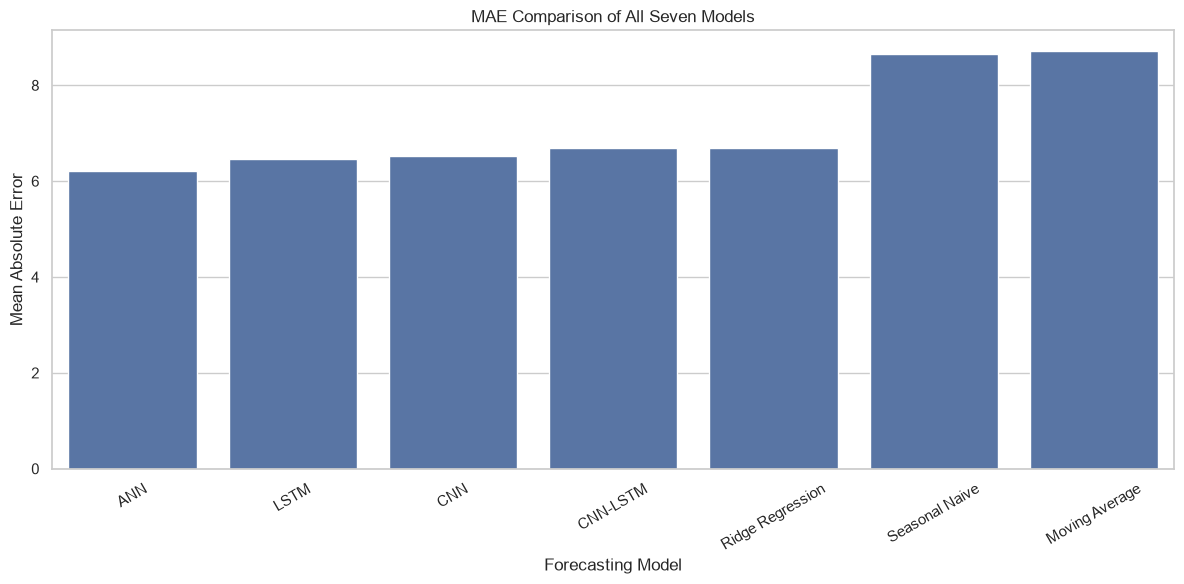

In [4]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results,
    x="Model",
    y="MAE"
)

plt.title("MAE Comparison of All Seven Models")
plt.xlabel("Forecasting Model")
plt.ylabel("Mean Absolute Error")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

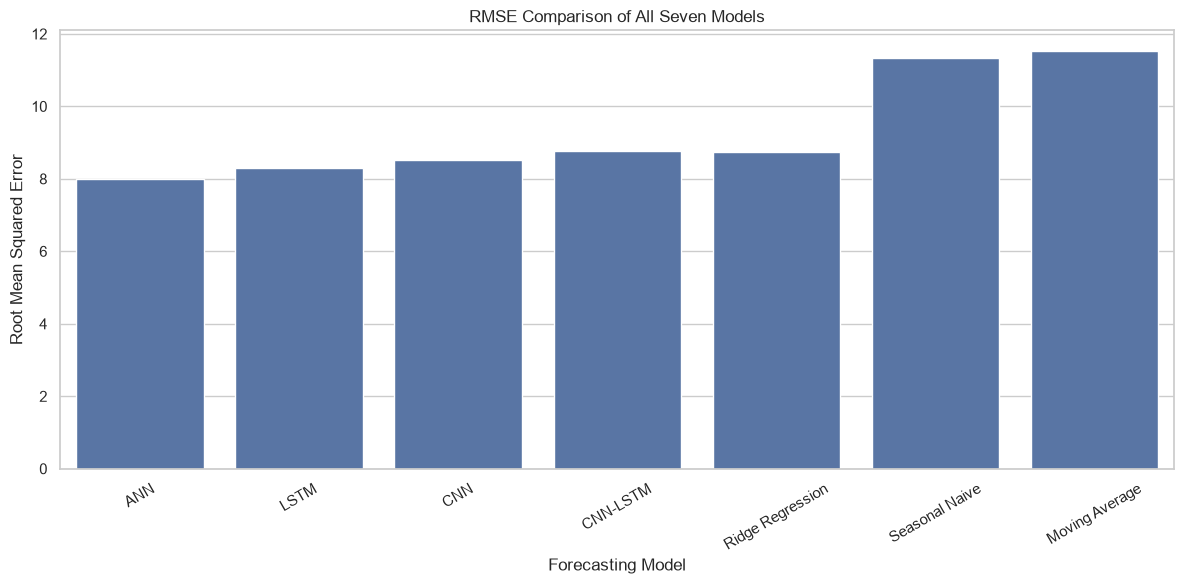

In [5]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison of All Seven Models")
plt.xlabel("Forecasting Model")
plt.ylabel("Root Mean Squared Error")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

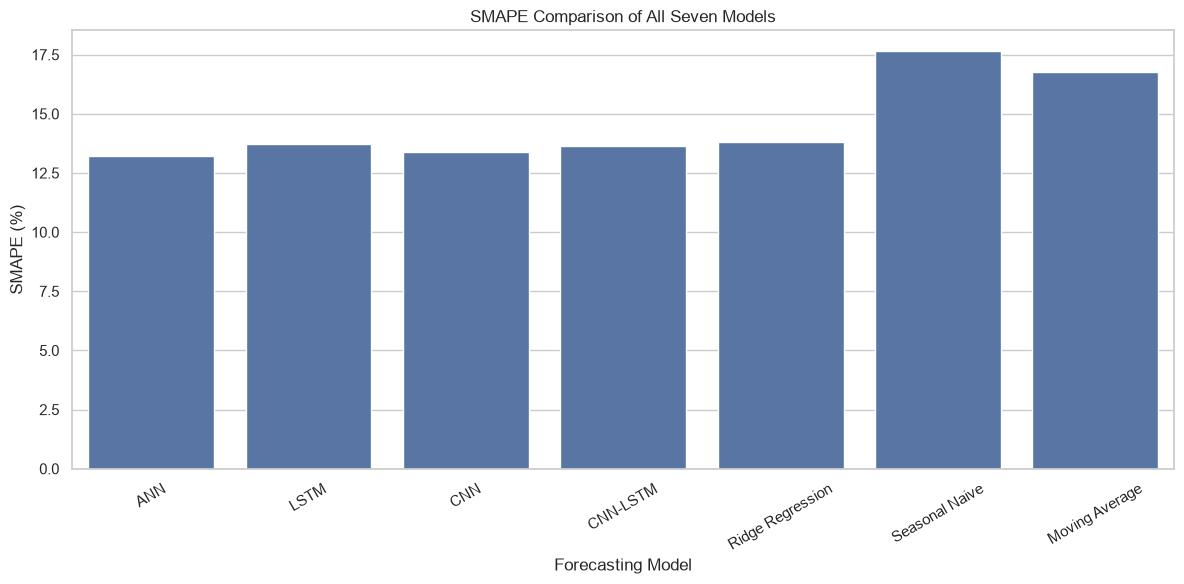

In [6]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results,
    x="Model",
    y="SMAPE"
)

plt.title("SMAPE Comparison of All Seven Models")
plt.xlabel("Forecasting Model")
plt.ylabel("SMAPE (%)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [7]:
best_model = results.iloc[0]

print("BEST MODEL ON VALIDATION DATA")
print("-----------------------------")

print("Model:", best_model["Model"])
print("MAE:", best_model["MAE"])
print("RMSE:", best_model["RMSE"])
print("SMAPE:", best_model["SMAPE"])

BEST MODEL ON VALIDATION DATA
-----------------------------
Model: ANN
MAE: 6.216330528259277
RMSE: 7.993874111807721
SMAPE: 13.203190747971473


In [8]:
reports_path = Path("../reports")

reports_path.mkdir(
    parents=True,
    exist_ok=True
)

results.to_csv(
    reports_path / "final_validation_comparison.csv",
    index=False
)

print("Final validation comparison saved!")

Final validation comparison saved!
